# ecDNA replication timing and completion-time bounds

This notebook analyses Repli-seq timing profiles for the COLO 320DM ecDNA system and compares stochastic DNAscape simulations with theoretical completion-time bounds.

The main workflow is:

1. read five S-phase Repli-seq bigWig tracks, `S1` to `S5`;
2. infer a continuous replication timing curve;
3. polish the curve by interpolation, smoothing and rescaling;
4. fit a spatial initiation landscape with `dnascape`;
5. simulate stochastic replication realisations;
6. compute Proposition 1 completion-time bounds on the torus $T_L$, the full line $\mathbb{R}$ and the half-line $\mathbb{R}_+$;
7. generate timing, firing-rate, replicated-fraction and bound-comparison plots.

The primary biological test case is the COLO 320DM c-MYC/ecDNA interval. The matched controls are COLO 320HSR and RPE-1 over the same chromosome 8 region.

## 1. Imports and global settings

The notebook assumes that `dnascape` is installed and that the Repli-seq bigWig files are available under `data/repliseq/`, with names such as `DM_S1_10000.bw`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pybigtools

# DNAscape core functions: rfit, rsim, plotf, rescale, etc.
from dnascape import *

plt.rcParams.update({
    "figure.figsize": (7.0, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
})

DATA_DIR = Path("data/repliseq")
FIGURE_DIR = Path("figures")
CACHE_DIR = Path("replication_timing")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

S_PHASE_BINS = ("S1", "S2", "S3", "S4", "S5")

## 2. Dataset registry

The exact c-MYC/ecDNA interval is the main region for the theoretical comparison. The broader chromosome 8 window is useful for reproducing the paper-style visualisation. The chromosome 20 region is a non-ecDNA control region.

In [2]:
DATASETS = {
    "DM_ECDNA_EXACT": {
        "label": "COLO 320DM, c-MYC/ecDNA interval",
        "short_label": "DM ecDNA",
        "cell_line": "DM",
        "chrom": "chr8",
        "start": 126_425_747,
        "end": 127_997_820,
        "resolution": 10_000,
        "fit_periodic": True,
        "sim_periodic": True,
        "bound_geometries": ("torus", "line", "halfline"),
        "notes": "Primary circular ecDNA test case.",
    },
    "HSR_MATCHED_EXACT": {
        "label": "COLO 320HSR, matched c-MYC interval",
        "short_label": "HSR matched",
        "cell_line": "HSR",
        "chrom": "chr8",
        "start": 126_425_747,
        "end": 127_997_820,
        "resolution": 10_000,
        "fit_periodic": False,
        "sim_periodic": False,
        "bound_geometries": ("line", "halfline"),
        "notes": "Patient-matched chromosomal reintegration comparison.",
    },
    "RPE1_MATCHED_EXACT": {
        "label": "RPE-1, matched chr8 c-MYC interval",
        "short_label": "RPE-1 matched",
        "cell_line": "RPE1",
        "chrom": "chr8",
        "start": 126_425_747,
        "end": 127_997_820,
        "resolution": 10_000,
        "fit_periodic": False,
        "sim_periodic": False,
        "bound_geometries": ("line", "halfline"),
        "notes": "Normal diploid chromosomal control.",
    },
    "DM_CHR8_CONTEXT": {
        "label": "COLO 320DM, broader chr8 c-MYC context",
        "short_label": "DM chr8 context",
        "cell_line": "DM",
        "chrom": "chr8",
        "start": 124_000_000,
        "end": 131_000_000,
        "resolution": 10_000,
        "fit_periodic": True,
        "sim_periodic": True,
        "bound_geometries": ("torus", "line", "halfline"),
        "notes": "Paper-style 7 Mb c-MYC/ecDNA visualisation window.",
    },
    "HSR_CHR8_CONTEXT": {
        "label": "COLO 320HSR, broader chr8 c-MYC context",
        "short_label": "HSR chr8 context",
        "cell_line": "HSR",
        "chrom": "chr8",
        "start": 124_000_000,
        "end": 131_000_000,
        "resolution": 10_000,
        "fit_periodic": False,
        "sim_periodic": False,
        "bound_geometries": ("line", "halfline"),
        "notes": "Matched chromosomal comparison over the 7 Mb window.",
    },
    "RPE1_CHR8_CONTEXT": {
        "label": "RPE-1, broader chr8 c-MYC context",
        "short_label": "RPE-1 chr8 context",
        "cell_line": "RPE1",
        "chrom": "chr8",
        "start": 124_000_000,
        "end": 131_000_000,
        "resolution": 10_000,
        "fit_periodic": False,
        "sim_periodic": False,
        "bound_geometries": ("line", "halfline"),
        "notes": "Normal chromosomal comparison over the 7 Mb window.",
    },
    "DM_CHR20_CONTROL": {
        "label": "COLO 320DM, chr20 control region",
        "short_label": "DM chr20 control",
        "cell_line": "DM",
        "chrom": "chr20",
        "start": 40_000_000,
        "end": 50_000_000,
        "resolution": 10_000,
        "fit_periodic": False,
        "sim_periodic": False,
        "bound_geometries": ("line", "halfline"),
        "notes": "Non-ecDNA control region.",
    },
}

# Main default run. Add or remove keys as needed.
RUN_KEYS = [
    "DM_ECDNA_EXACT",
    "HSR_MATCHED_EXACT",
    "RPE1_MATCHED_EXACT",
]

# For the broader paper-style context plots, use for example:
# RUN_KEYS = ["DM_CHR8_CONTEXT", "HSR_CHR8_CONTEXT", "RPE1_CHR8_CONTEXT", "DM_CHR20_CONTROL"]

### File availability check

In [3]:
def expected_bigwig_files(cfg, data_dir=DATA_DIR):
    return [
        data_dir / f"{cfg['cell_line']}_{sbin}_{cfg['resolution']}.bw"
        for sbin in S_PHASE_BINS
    ]


def check_required_files(run_keys=RUN_KEYS, data_dir=DATA_DIR):
    rows = []

    for key in run_keys:
        cfg = DATASETS[key]
        for path in expected_bigwig_files(cfg, data_dir=data_dir):
            rows.append({
                "dataset": key,
                "label": cfg["label"],
                "file": str(path),
                "exists": path.exists(),
            })

    return pd.DataFrame(rows)


file_check = check_required_files(RUN_KEYS)
file_check

,dataset,label,file,exists
0,DM_ECDNA_EXACT,"COLO 320DM, c-MYC/ecDNA interval",data\repliseq\DM_S1_10000.bw,True
1,DM_ECDNA_EXACT,"COLO 320DM, c-MYC/ecDNA interval",data\repliseq\DM_S2_10000.bw,True
2,DM_ECDNA_EXACT,"COLO 320DM, c-MYC/ecDNA interval",data\repliseq\DM_S3_10000.bw,True
3,DM_ECDNA_EXACT,"COLO 320DM, c-MYC/ecDNA interval",data\repliseq\DM_S4_10000.bw,True
4,DM_ECDNA_EXACT,"COLO 320DM, c-MYC/ecDNA interval",data\repliseq\DM_S5_10000.bw,True
5,HSR_MATCHED_EXACT,"COLO 320HSR, matched c-MYC interval",data\repliseq\HSR_S1_10000.bw,True
6,HSR_MATCHED_EXACT,"COLO 320HSR, matched c-MYC interval",data\repliseq\HSR_S2_10000.bw,True
7,HSR_MATCHED_EXACT,"COLO 320HSR, matched c-MYC interval",data\repliseq\HSR_S3_10000.bw,True
8,HSR_MATCHED_EXACT,"COLO 320HSR, matched c-MYC interval",data\repliseq\HSR_S4_10000.bw,True
9,HSR_MATCHED_EXACT,"COLO 320HSR, matched c-MYC interval",data\repliseq\HSR_S5_10000.bw,True


## 3. Repli-seq timing extraction

For each genomic bin, the five S-phase signals are normalised, converted to a cumulative distribution, and fitted with a sigmoid. The fitted midpoint is used as a raw timing value. This matches the logic of the original exploratory notebook while making the file handling reusable.

In [4]:
def sigmoid(x, k, x0):
    return 1.0 / (1.0 + np.exp(-k * (x - x0)))


def read_bigwig_bin_mean(bw, chrom, start, end):
    vals = bw.values(chrom, int(start), int(end))

    if vals is None:
        return np.nan

    vals = np.asarray(
        [np.nan if v is None else float(v) for v in vals],
        dtype=float,
    )

    if vals.size == 0:
        return np.nan

    return np.nanmean(vals)


def compute_timing_curve(chrom, start, end, cell_line="DM", resolution=10_000,
                         data_dir=DATA_DIR, s_phase_bins=S_PHASE_BINS):
    x_bins = np.arange(1, len(s_phase_bins) + 1, dtype=float)

    bw_files = [
        pybigtools.open(str(data_dir / f"{cell_line}_{sbin}_{resolution}.bw"))
        for sbin in s_phase_bins
    ]

    positions = np.arange(start, end, resolution, dtype=int)
    rt_values = []

    try:
        for pos in positions:
            signals = np.array([
                read_bigwig_bin_mean(bw, chrom, pos, pos + resolution)
                for bw in bw_files
            ], dtype=float)

            if np.any(~np.isfinite(signals)) or np.nansum(signals) <= 0:
                rt_values.append(np.nan)
                continue

            norm_signals = signals / np.sum(signals)
            cumulative = np.cumsum(norm_signals)

            try:
                popt, _ = curve_fit(
                    sigmoid,
                    x_bins,
                    cumulative,
                    p0=(2.0, 3.0),
                    bounds=([0.1, 1.0], [10.0, len(s_phase_bins)]),
                    maxfev=10_000,
                )
                _, x0 = popt
                rt_values.append(x0)
            except RuntimeError:
                rt_values.append(np.nan)

    finally:
        for bw in bw_files:
            bw.close()

    return positions, np.asarray(rt_values, dtype=float)


def compute_timing_curve_from_config(cfg, data_dir=DATA_DIR):
    return compute_timing_curve(
        chrom=cfg["chrom"],
        start=cfg["start"],
        end=cfg["end"],
        cell_line=cfg["cell_line"],
        resolution=cfg["resolution"],
        data_dir=data_dir,
    )

## 4. Curve polishing

The raw timing curve is interpolated, smoothed and rescaled to a time interval in minutes. The default refinement converts 10 kb input bins into 1 kb grid spacing.

In [5]:
def refinef_local(x, resolution_factor=1, mode="smooth"):
    x = np.asarray(x, dtype=float)

    if len(x) == 0:
        return x

    if resolution_factor <= 0:
        raise ValueError("resolution_factor must be positive")

    m = max(1, int(round(len(x) * resolution_factor)))
    u = np.clip(np.arange(m) / resolution_factor, 0, len(x) - 1)

    if mode == "smooth":
        return np.interp(u, np.arange(len(x)), x)

    if mode == "const":
        return x[np.clip(np.floor(u + 0.5).astype(int), 0, len(x) - 1)]

    raise ValueError("mode must be 'smooth' or 'const'")


def smoothf_local(data, window=50):
    data = np.asarray(data, dtype=float)
    n = len(data)

    if n == 0:
        return data

    window = int(max(1, min(window, n)))
    kernel = np.ones(window, dtype=float)

    # Use reflect padding to avoid strong edge artefacts.
    left = data[1:window + 1][::-1] if n > 1 else data
    right = data[-window - 1:-1][::-1] if n > 1 else data
    padded = np.concatenate([left, data, right])

    smoothed = np.convolve(padded, kernel / kernel.sum(), mode="same")
    return smoothed[len(left):len(left) + n]


def fill_nan_linear(y):
    y = np.asarray(y, dtype=float)
    x = np.arange(len(y))
    ok = np.isfinite(y)

    if ok.sum() < 2:
        raise ValueError("Not enough finite timing values to interpolate.")

    return np.interp(x, x[ok], y[ok])


def prepare_timing_curve(positions_raw, timing_raw, resolution=10_000,
                         refine_factor=10, smooth_window=50,
                         timing_range=(60, 10), slice_stop=None):
    timing_filled = fill_nan_linear(timing_raw)

    timing = refinef_local(timing_filled, resolution_factor=refine_factor)
    timing = smoothf_local(timing, window=smooth_window)
    timing = np.asarray(rescale(timing, timing_range), dtype=float)

    positions = refinef_local(positions_raw, resolution_factor=refine_factor)

    if slice_stop is not None:
        timing = timing[:slice_stop]
        positions = positions[:slice_stop]

    dx_kb = resolution / refine_factor / 1000.0

    return {
        "positions_bp": positions,
        "positions_kb": positions / 1000.0,
        "timing_min": timing,
        "dx_kb": dx_kb,
        "refine_factor": refine_factor,
        "smooth_window": smooth_window,
        "timing_range": timing_range,
    }

## 5. Proposition 1 completion-time bounds

The geometry enters only through the causal-cone width:

\[
w_{T_L}(\sigma)=\min\{2v_{\min}\sigma,L\},\qquad
w_{\mathbb{R}}(\sigma)=2v_{\min}\sigma,\qquad
w_{\mathbb{R}_+}(\sigma)=v_{\min}\sigma.
\]

For $\mathbb{R}$ and $\mathbb{R}_+$, a finite fitted initiation landscape must be extended outside the observed window. Here the default is a periodic extension of the fitted profile. This keeps the initiation landscape fixed and isolates the effect of geometry.

In [7]:
GEOMETRY_LABELS = {
    "torus": r"Torus $T_L$",
    "line": r"Full line $\mathbb{R}$",
    "halfline": r"Half-line $\mathbb{R}_+$",
}


def _higher_quantiles(x, q):
    x = np.sort(np.asarray(x, dtype=float), axis=0)
    n = x.shape[0]
    q = np.asarray(q, dtype=float)
    k = np.clip(np.ceil(q * n).astype(int) - 1, 0, n - 1)
    return x[k]


def _width(sigma, L, vmin, geometry="torus"):
    sigma = np.asarray(sigma, dtype=float)

    if geometry == "torus":
        return np.minimum(2.0 * vmin * sigma, L)

    if geometry == "line":
        return 2.0 * vmin * sigma

    if geometry == "halfline":
        return vmin * sigma

    raise ValueError("geometry must be 'torus', 'line', or 'halfline'")


def _torus_local_mass(I, lengths, dx=1.0):
    I = np.asarray(I, dtype=float)
    lengths = np.atleast_1d(np.asarray(lengths, dtype=float))

    n = len(I)
    L = n * dx
    idx = np.arange(n)

    mass = np.concatenate([I, I])
    prefix = np.concatenate([[0.0], np.cumsum(mass)])

    out = np.empty_like(lengths, dtype=float)

    for k, r in enumerate(lengths):
        if r <= 0:
            out[k] = 0.0
            continue

        if r >= L:
            out[k] = dx * np.sum(I)
            continue

        u = r / dx
        q = int(np.floor(u))
        frac = u - q

        totals = dx * (prefix[idx + q] - prefix[idx])

        if frac > 0:
            totals = totals + frac * dx * I[(idx + q) % n]

        out[k] = np.min(totals)

    return out


def _periodic_extension_local_mass(I, lengths, dx=1.0):
    I = np.asarray(I, dtype=float)
    lengths = np.atleast_1d(np.asarray(lengths, dtype=float))

    n = len(I)
    L = n * dx
    total_mass = dx * np.sum(I)

    out = np.empty_like(lengths, dtype=float)

    for k, r in enumerate(lengths):
        if r <= 0:
            out[k] = 0.0
            continue

        n_periods = int(np.floor(r / L))
        remainder = r - n_periods * L

        out[k] = n_periods * total_mass

        if remainder > 1e-12:
            out[k] += _torus_local_mass(I, [remainder], dx=dx)[0]

    return out


def _local_mass(I, lengths, dx=1.0, geometry="torus"):
    if geometry == "torus":
        return _torus_local_mass(I, lengths, dx=dx)

    if geometry in {"line", "halfline"}:
        return _periodic_extension_local_mass(I, lengths, dx=dx)

    raise ValueError("geometry must be 'torus', 'line', or 'halfline'")


def proposition1_curve(frates, vmin=1.4, dx=1.0, geometry="torus",
                       rhs_max=None, num_t=4000):
    I = np.asarray(frates, dtype=float)

    if I.ndim != 1:
        raise ValueError("frates must be a 1D array")

    if np.any(I < 0):
        raise ValueError("frates must be nonnegative")

    if vmin <= 0 or dx <= 0:
        raise ValueError("vmin and dx must be positive")

    L = len(I) * dx
    total_mass = dx * np.sum(I)

    if total_mass <= 0:
        raise ValueError("Total initiation mass must be positive.")

    if rhs_max is None:
        rhs_max = np.log(1.0 / 1e-4)

    # A first upper-time guess. It is enlarged automatically if needed.
    t_wrap = L / (2.0 * vmin)
    t_max = t_wrap + rhs_max / max(total_mass, 1e-12) + dx / vmin

    while True:
        t = np.linspace(0.0, t_max, num_t)
        r = _width(t, L=L, vmin=vmin, geometry=geometry)

        r_unique, inv = np.unique(r, return_inverse=True)
        m_unique = _local_mass(I, r_unique, dx=dx, geometry=geometry)
        mI = m_unique[inv]

        dt = np.diff(t)
        F = np.empty_like(t)
        F[0] = 0.0
        F[1:] = np.cumsum(0.5 * (mI[:-1] + mI[1:]) * dt)

        if F[-1] >= rhs_max:
            break

        t_max *= 2.0

    return {
        "I": I,
        "L": L,
        "dx": dx,
        "vmin": float(vmin),
        "geometry": geometry,
        "geometry_label": GEOMETRY_LABELS[geometry],
        "t": t,
        "r": r,
        "mI": mI,
        "F": F,
    }


def bound_proposition1(eps, frates, vmin=1.4, dx=1.0,
                       geometry="torus", num_t=4000):
    eps = np.asarray(eps, dtype=float)

    if np.any((eps <= 0) | (eps >= 1)):
        raise ValueError("eps must lie strictly in (0, 1).")

    rhs = np.log(1.0 / eps)

    aux = proposition1_curve(
        frates=frates,
        vmin=vmin,
        dx=dx,
        geometry=geometry,
        rhs_max=float(np.max(rhs)),
        num_t=num_t,
    )

    T_bound = np.interp(rhs, aux["F"], aux["t"])

    return T_bound, aux


def compare_proposition1(frates, rep_times_per_sim=None, fork_speed=1.4,
                         dx=1.0, eps_grid=None, geometry="torus",
                         num_t=4000):
    if eps_grid is None:
        eps_grid = np.geomspace(1e-4, 0.99, 100)

    eps_grid = np.asarray(eps_grid, dtype=float)

    T_theory, aux = bound_proposition1(
        eps=eps_grid,
        frates=frates,
        vmin=fork_speed,
        dx=dx,
        geometry=geometry,
        num_t=num_t,
    )

    out = {
        "eps": eps_grid,
        "T_theory": T_theory,
        "aux": aux,
        "geometry": geometry,
        "geometry_label": GEOMETRY_LABELS[geometry],
    }

    if rep_times_per_sim is not None:
        tau = np.asarray(rep_times_per_sim, dtype=float)

        if tau.ndim != 2:
            raise ValueError("rep_times_per_sim must have shape (n_sims, n_pos).")

        if tau.shape[1] != len(frates):
            raise ValueError("rep_times_per_sim.shape[1] must equal len(frates).")

        q = 1.0 - eps_grid
        T_empirical = _higher_quantiles(tau, q).max(axis=1)
        out["T_empirical"] = T_empirical

    return out

## 6. Plotting helpers

In [8]:
def safe_filename(text):
    return (
        text.replace(" ", "_")
            .replace("/", "_")
            .replace(",", "")
            .replace("(", "")
            .replace(")", "")
            .replace("$", "")
            .replace("\\", "")
            .replace("+", "plus")
    )


def plot_replicated_fraction_map(rep_times_per_sim, positions_kb=None,
                                 nt=300, ylims=None, title=None):
    tau = np.asarray(rep_times_per_sim, dtype=float)

    if tau.ndim != 2:
        raise ValueError("rep_times_per_sim must have shape (n_sims, n_pos).")

    n_sims, n_pos = tau.shape

    if positions_kb is None:
        x = np.arange(n_pos)
        xlabel = "Position"
    else:
        x = np.asarray(positions_kb, dtype=float)
        xlabel = "Chromosome position (kb)"

    tmin = max(0.0, np.nanmin(tau))
    tmax = np.nanmax(tau)
    t_grid = np.linspace(tmin, tmax, nt)

    S = (tau[None, :, :] <= t_grid[:, None, None]).mean(axis=1)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    im = ax.imshow(
        S,
        aspect="auto",
        origin="lower",
        extent=[x[0], x[-1], t_grid[0], t_grid[-1]],
        vmin=0.0,
        vmax=1.0,
    )

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"Replicated fraction $f(x,t)$")

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Replication time (min)")
    ax.set_title(title or r"Empirical replicated fraction $f(x,t)$")

    if ylims is not None:
        ax.set_ylim(*ylims)
    else:
        ax.invert_yaxis()

    plt.tight_layout()
    return fig, ax, x, t_grid, S


def plot_geometry_bounds(results_by_geometry, title=None, empiricalQ=True):
    fig, ax = plt.subplots(figsize=(6.8, 4.6))

    for geometry, res in results_by_geometry.items():
        ax.plot(
            res["eps"],
            res["T_theory"],
            label=f"{GEOMETRY_LABELS[geometry]} bound",
        )

    if empiricalQ:
        first_res = next(iter(results_by_geometry.values()))

        if "T_empirical" in first_res:
            ax.plot(
                first_res["eps"],
                first_res["T_empirical"],
                linestyle="--",
                label="empirical simulation",
            )

    ax.set_xscale("log")
    ax.set_xlabel(r"Tolerance $\varepsilon$")
    ax.set_ylabel(r"Completion time $T_\varepsilon$ (min)")
    ax.set_title(title or "Completion-time bounds by geometry")
    ax.legend()
    plt.tight_layout()

    return fig, ax


def plot_bound_tightness(result, title=None):
    if "T_empirical" not in result:
        raise ValueError("This result has no empirical simulation curve.")

    eps = result["eps"]
    theory = result["T_theory"]
    empirical = result["T_empirical"]

    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ax.plot(eps, theory / empirical)
    ax.axhline(1.0, linestyle="--", linewidth=1)

    ax.set_xscale("log")
    ax.set_xlabel(r"Tolerance $\varepsilon$")
    ax.set_ylabel(r"Theoretical / empirical $T_\varepsilon$")
    ax.set_title(title or f"Bound tightness: {result['geometry_label']}")
    plt.tight_layout()

    return fig, ax


def plot_local_mass(result, title=None):
    aux = result["aux"]

    fig, ax = plt.subplots(figsize=(6.8, 4.2))
    ax.plot(aux["r"], aux["mI"])

    ax.set_xlabel("Arc or interval length r (kb)")
    ax.set_ylabel(r"Local initiation mass $m_I(r)$")
    ax.set_title(title or f"Local initiation-mass function: {aux['geometry_label']}")
    plt.tight_layout()

    return fig, ax

## 7. Analysis functions

The following functions run one dataset end to end and save the standard plots.

In [9]:
def analyse_dataset(cfg, fork_speed=1.4, sim_number=1000,
                    refine_factor=10, smooth_window=50,
                    timing_range=(60, 10), eps_grid=None,
                    slice_stop=None, num_t_bound=4000,
                    save_figures=True):
    if eps_grid is None:
        eps_grid = np.geomspace(1e-4, 0.99, 100)

    print(f"Processing: {cfg['label']}")
    print(f"Region: {cfg['chrom']}:{cfg['start']}-{cfg['end']}")

    positions_raw, timing_raw = compute_timing_curve_from_config(cfg)

    prepared = prepare_timing_curve(
        positions_raw=positions_raw,
        timing_raw=timing_raw,
        resolution=cfg["resolution"],
        refine_factor=refine_factor,
        smooth_window=smooth_window,
        timing_range=timing_range,
        slice_stop=slice_stop,
    )

    timedata = prepared["timing_min"]
    positions_kb = prepared["positions_kb"]
    dx_kb = prepared["dx_kb"]

    frates = rfit(
        "replication_timing",
        "firing_rate",
        source=timedata,
        fork_speed=fork_speed,
        maxiter=10,
        fit_step=2,
        perQ=cfg["fit_periodic"],
    )

    simres = rsim(
        ori_rate=frates,
        fork_speed=fork_speed,
        sim_number=sim_number,
        perQ=cfg["sim_periodic"],
        time_statsQ=True,
        time_stats_xtQ=False,
        time_stats_densQ=None,
    )

    rep_times_per_sim = simres["rep_times_per_sim"]

    bounds = {}

    for geometry in cfg["bound_geometries"]:
        bounds[geometry] = compare_proposition1(
            frates=frates,
            rep_times_per_sim=rep_times_per_sim,
            fork_speed=fork_speed,
            dx=dx_kb,
            eps_grid=eps_grid,
            geometry=geometry,
            num_t=num_t_bound,
        )

    result = {
        "config": cfg,
        "positions_raw": positions_raw,
        "timing_raw": timing_raw,
        "prepared": prepared,
        "timedata": timedata,
        "frates": frates,
        "simres": simres,
        "rep_times_per_sim": rep_times_per_sim,
        "bounds": bounds,
        "fork_speed": fork_speed,
        "sim_number": sim_number,
        "eps_grid": eps_grid,
    }

    if save_figures:
        prefix = safe_filename(cfg["short_label"])

        # Original-style firing-rate plot.
        plotf(
            frates,
            logyQ=True,
            x_array=positions_kb,
            invyQ=True,
            xtitle="Chromosome position (kb)",
            ytitle="Firing rate",
            labels=[cfg["label"]],
            saveQ=False,
        )
        plt.savefig(FIGURE_DIR / f"{prefix}_firing_rate.pdf", bbox_inches="tight")
        plt.show()

        # Original-style Repli-seq versus simulation timing plot.
        plotf(
            timedata,
            simres["replication_timing"],
            x_array=positions_kb,
            invyQ=True,
            xtitle="Chromosome position (kb)",
            ytitle="Replication timing (min)",
            labels=["Repli-seq", "Simulation"],
            saveQ=False,
        )
        plt.savefig(FIGURE_DIR / f"{prefix}_timing_repliseq_vs_simulation.pdf", bbox_inches="tight")
        plt.show()

        # Replicated fraction map.
        fig, ax, *_ = plot_replicated_fraction_map(
            rep_times_per_sim,
            positions_kb=positions_kb,
            nt=300,
            title=f"{cfg['label']}: empirical replicated fraction",
        )
        fig.savefig(FIGURE_DIR / f"{prefix}_replicated_fraction_map.pdf", bbox_inches="tight")
        plt.show()

        # Geometry comparison plot.
        fig, ax = plot_geometry_bounds(
            bounds,
            title=f"{cfg['label']}: Proposition 1 bounds",
            empiricalQ=True,
        )
        fig.savefig(FIGURE_DIR / f"{prefix}_bounds_by_geometry.pdf", bbox_inches="tight")
        plt.show()

        # Tightness plot for the first available geometry.
        primary_geometry = cfg["bound_geometries"][0]
        fig, ax = plot_bound_tightness(
            bounds[primary_geometry],
            title=f"{cfg['label']}: tightness of {GEOMETRY_LABELS[primary_geometry]} bound",
        )
        fig.savefig(FIGURE_DIR / f"{prefix}_bound_tightness_{primary_geometry}.pdf", bbox_inches="tight")
        plt.show()

        # Local initiation mass for each geometry.
        for geometry, bound_result in bounds.items():
            fig, ax = plot_local_mass(
                bound_result,
                title=f"{cfg['label']}: $m_I(r)$ for {GEOMETRY_LABELS[geometry]}",
            )
            fig.savefig(FIGURE_DIR / f"{prefix}_local_mass_{geometry}.pdf", bbox_inches="tight")
            plt.show()

    return result


def run_datasets(run_keys=RUN_KEYS, **kwargs):
    results = {}

    for key in run_keys:
        results[key] = analyse_dataset(DATASETS[key], **kwargs)

    return results

## 8. Run the analysis

This cell loops over `RUN_KEYS`. For a quick first run, keep `sim_number` small. For final figures, increase to `10_000` if computation time allows.

Processing: COLO 320DM, c-MYC/ecDNA interval
Region: chr8:126425747-127997820
[1000/1000]  Elapsed: 00:00:21  ETA: 00:00:00E: 4.8466e-01

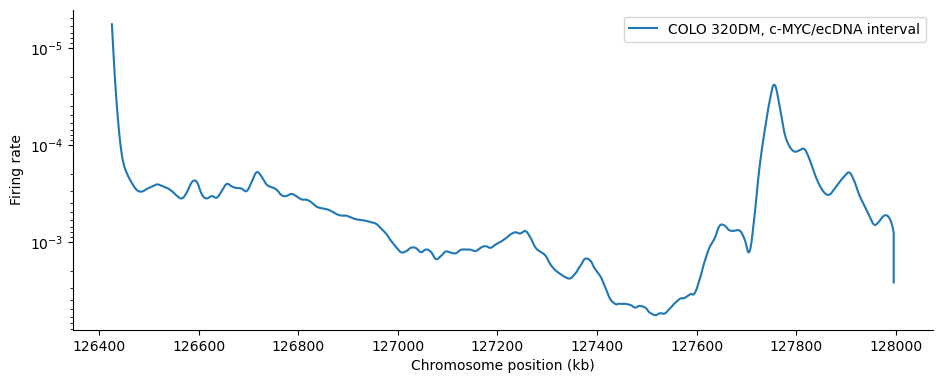

<Figure size 700x450 with 0 Axes>

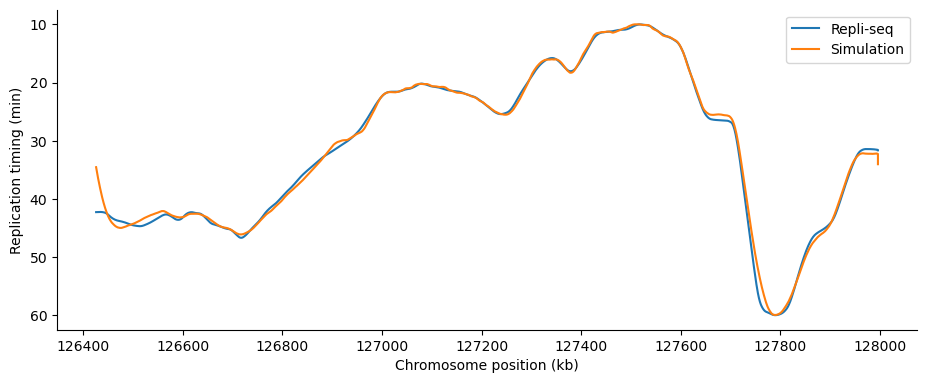

<Figure size 700x450 with 0 Axes>

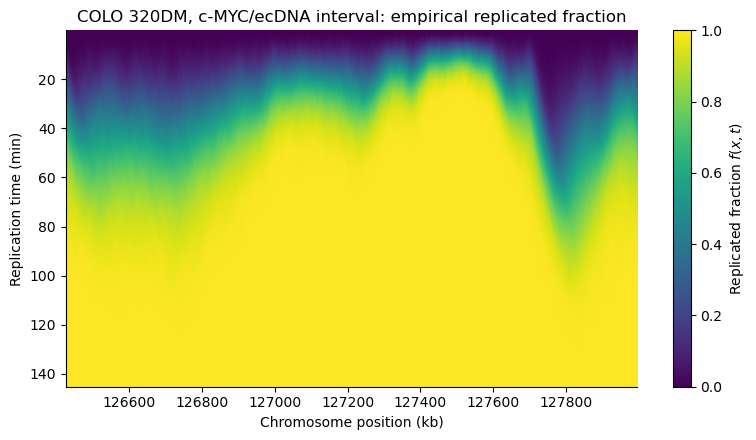

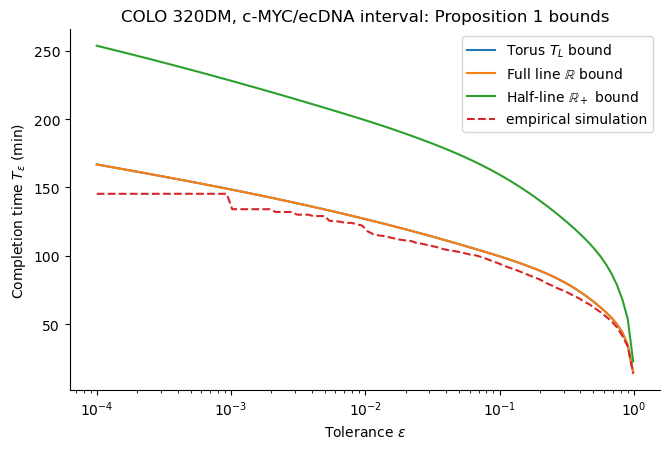

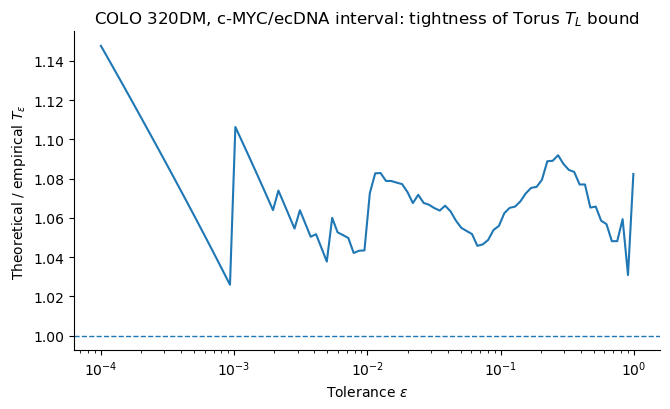

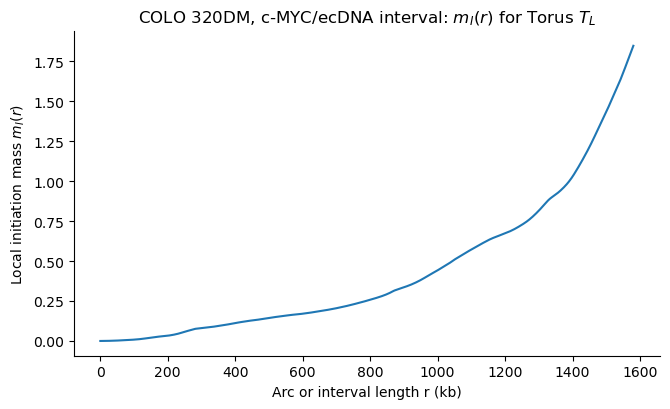

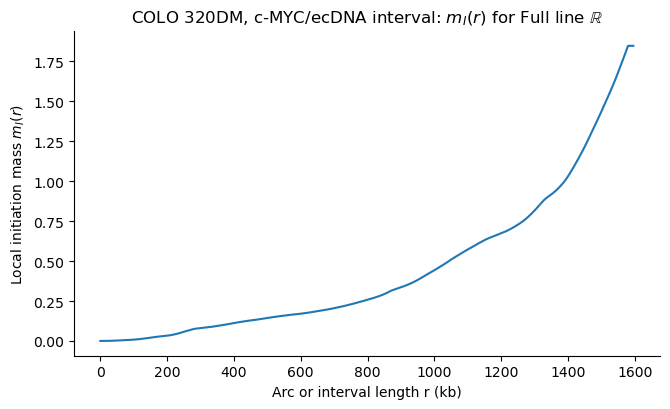

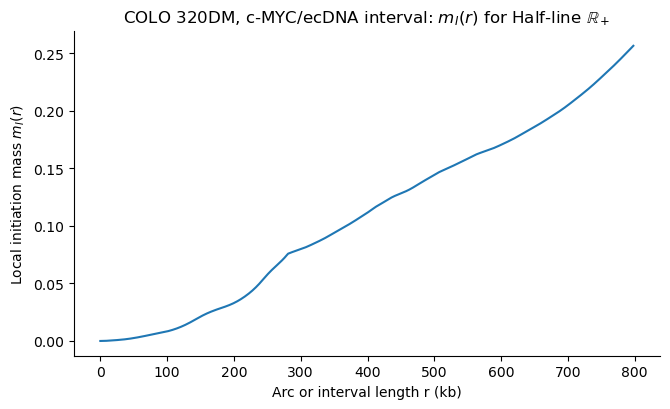

Processing: COLO 320HSR, matched c-MYC interval
Region: chr8:126425747-127997820


KeyError: 'No chromomsome with name `chr8` found.'

In [10]:
eps_grid = np.geomspace(1e-4, 0.99, 100)

all_results = run_datasets(
    RUN_KEYS,
    fork_speed=1.4,
    sim_number=1000,
    refine_factor=10,
    smooth_window=50,
    timing_range=(60, 10),
    eps_grid=eps_grid,
    num_t_bound=4000,
    save_figures=True,
)

## 9. Summary table

This table samples the empirical and theoretical completion-time curves at a few tolerance values.

In [ ]:
def completion_summary_table(results, eps_values=(0.1, 0.05, 0.01, 0.001)):
    rows = []

    for key, result in results.items():
        cfg = result["config"]

        for geometry, bound_result in result["bounds"].items():
            eps = bound_result["eps"]
            theory = bound_result["T_theory"]

            empirical = bound_result.get("T_empirical", None)

            for eps0 in eps_values:
                theory0 = np.interp(eps0, eps, theory)

                row = {
                    "dataset": key,
                    "label": cfg["label"],
                    "geometry": geometry,
                    "geometry_label": GEOMETRY_LABELS[geometry],
                    "epsilon": eps0,
                    "T_theory": theory0,
                }

                if empirical is not None:
                    emp0 = np.interp(eps0, eps, empirical)
                    row["T_empirical"] = emp0
                    row["theory_to_empirical"] = theory0 / emp0

                rows.append(row)

    return pd.DataFrame(rows)


summary = completion_summary_table(all_results)
summary

## 10. Optional: compare geometries for a single fitted initiation landscape

This is the cleanest topology-only comparison: use the same fitted initiation landscape and change only the geometric width function. For ecDNA, the torus is the biological geometry. The full line and half-line curves act as idealised linear controls.

In [ ]:
key = "DM_ECDNA_EXACT"

if key in all_results:
    result = all_results[key]
    bounds = result["bounds"]

    fig, ax = plot_geometry_bounds(
        bounds,
        title="Topology-only comparison on the COLO 320DM c-MYC/ecDNA initiation landscape",
        empiricalQ=True,
    )
    fig.savefig(FIGURE_DIR / "DM_ecDNA_topology_only_TL_R_Rplus.pdf", bbox_inches="tight")
    plt.show()
else:
    print(f"{key} has not been run. Add it to RUN_KEYS and rerun the analysis.")

## Notes on interpretation

For the COLO 320DM ecDNA interval, the torus bound is the natural theoretical object because the amplicon is circular. The full-line bound uses the same two-sided causal-cone expansion as an unbounded chromosome-like domain, without wrap-around. The half-line bound is a conservative one-sided boundary case.

The empirical curve plotted above comes from the DNAscape stochastic simulations configured by `sim_periodic`. For the ecDNA dataset this is periodic. Therefore, the torus comparison is the direct empirical/theoretical match. The full-line and half-line curves are best interpreted as geometry controls unless separate simulations with matching boundary assumptions are implemented.